# RQ5: Weather as a Predictor of Energy

**Research Question:** How accurately can a combination of daily temperature and sunshine duration predict the overall Energy level of the German Top 100?

---

## 1. Method

### 1.1 Data Aggregation

Track-level data was collapsed to **one row per day** (1,825 days total), with daily Energy computed as the mean across all charting tracks. Weather features (`temperature_mean_c`, `sunshine_hours`) are day-level constants.

### 1.2 TimeSeriesSplit Cross-Validation

**5-fold chronological cross-validation** was used — training only on past data, testing on future data. This prevents the autocorrelation of daily charts from leaking between train and test sets, which would otherwise overstate predictive performance.

### 1.3 Models Evaluated (all on identical folds)

| Model | Role |
|---|---|
| **Mean baseline** | Predicts the training mean every time|
| **Persistence baseline** | Predicts yesterday's Energy|
| **Linear Regression** | Standard OLS with temperature and sunshine as predictors |
| **Gradient Boosting** | Nonlinear model to check if a flexible model captures structure linear regression misses |

### 1.4 Regression Analysis (Seasonal Interaction)

Nested OLS models with seasonal interactions to examine whether weather effects vary by season:

- **Model 1:** `Energy ~ Temperature + Precipitation + Sunshine + Season`
- **Model 2:** Model 1 + all weather × season interactions
- **F-test:** Compares whether interactions add significant explanatory power
- **VIF check:** Computed for all three weather predictors to ensure stable coefficient estimates

Note: Track 2 (seasonal regression) is independent of Track 1. It uses the w5-preprocessed dataset (with season column) and is not used to evaluate predictive accuracy it is purely explanatory. Refer the activity-diagram.

In [10]:
# Load result files produced by the Snakemake workflow
import json
import os
import pandas as pd
from IPython.display import Image, display

RESULTS_DIR = "../results/workflow_5"

# Track 1: predictive accuracy
predict_summary_path = os.path.join(RESULTS_DIR, "predict_summary.json")
predict_folds_path   = os.path.join(RESULTS_DIR, "predict_folds.csv")

# Track 2: seasonal regression
coefficients_path     = os.path.join(RESULTS_DIR, "coefficients.csv")
vif_path              = os.path.join(RESULTS_DIR, "vif.csv")
comparison_path       = os.path.join(RESULTS_DIR, "comparison.csv")
seasonal_slopes_path  = os.path.join(RESULTS_DIR, "seasonal_slopes.csv")
predictive_metrics_path = os.path.join(RESULTS_DIR, "predictive_metrics.csv")

with open(predict_summary_path) as f:
    predict_summary = json.load(f)

predict_folds    = pd.read_csv(predict_folds_path)
vif_table        = pd.read_csv(vif_path)
comparison_table = pd.read_csv(comparison_path)
seasonal_slopes  = pd.read_csv(seasonal_slopes_path)
predictive_metrics = pd.read_csv(predictive_metrics_path)

print("All result files loaded successfully. \n")
print(f"Best model: {predict_summary['best_model']} "
      f"(R² = {predict_summary['best_model_r2_mean']:.4f}, "
      f"beats baselines: {predict_summary['beats_all_baselines']})")

All result files loaded successfully. 

Best model: linear_regression (R² = -0.3798, beats baselines: False)


---
## 2. Predictive Accuracy

In [11]:
# Cross-validated performance summary table
rows = []
for model, stats in predict_summary["models"].items():
    rows.append({
        "Model": model,
        "R² (mean)": stats["r2_mean"],
        "R² (std)": stats["r2_std"],
        "RMSE (mean)": stats["rmse_mean"],
        "MAE (mean)": stats["mae_mean"],
        "Folds": stats["n_folds"],
    })

pd.DataFrame(rows)

,Model,R² (mean),R² (std),RMSE (mean),MAE (mean),Folds
0,baseline_mean,-0.5131,0.8408,0.03091,0.02394,5
1,baseline_persistence,0.7356,0.0621,0.01281,0.00824,5
2,gradient_boosting,-0.4268,0.6695,0.02994,0.02443,5
3,linear_regression,-0.3798,0.7494,0.02941,0.02381,5


**Interpretation**

The persistence baseline achieved a mean cross-validated R² of 0.7356, indicating that yesterday’s mean energy is a strong predictor of today’s mean energy across these folds. This is consistent with substantial continuity in chart composition, but it should not be interpreted as a causal proportion of variation explained by chart inertia. Additionally,  Linear regression (R² = −0.3798) and gradient boosting (R² = −0.4268) both yield negative R² hence the model is performing worse than the simple baseline of predicting the mean. A negative R² means the model is actively worse than predicting the training mean, weather features are adding noise, not signal. The standard deviations of the R² scores across folds are very large (linear regression: ±0.75, mean baseline: ±0.84). This means that the model's performance changes greatly depending on the time range being analyzed.

In [12]:
# Per-fold R² breakdown
predict_folds.pivot_table(
    index="fold", columns="model", values="r2"
).round(4)

model,baseline_mean,baseline_persistence,gradient_boosting,linear_regression
fold,,,,
0,-0.0079,0.7516,-0.0351,0.0542
1,-0.0526,0.6444,-0.1469,-0.0305
2,-2.0031,0.7863,-1.5507,-1.6845
3,-0.2874,0.7033,-0.5133,-0.3396
4,-0.2145,0.7924,0.1122,0.1017


**Interpretation**
The persistant baseline is the only model that performed more or less the same well across all folds with (R2 range: 0.644-0.792) this outlines the chart inertia is stable and solid signal regardless of time periodds.

Visibly fold 2 is an outlier driving negative cross-validated averages. The big drop of mean baseline and linear regression in that fold alone mean model's prediction were ddramatically worse than simply predicting the mean for that, understood this shift as a structural shift within the chart during that time window that weather feature cannot anticipate.

In fold 0 and r linear regression achieves R² = +0.054 and +0.102 respectively, and gradient boosting +0.112 in fold 4 the only folds where weather models produce positive R². This means weather has a weak positive predictive signal in certain periods but not consistently enough to be relied upon.

We can deduce that weather is a weak predictor on average and it's usefulness is highly period-dependent.

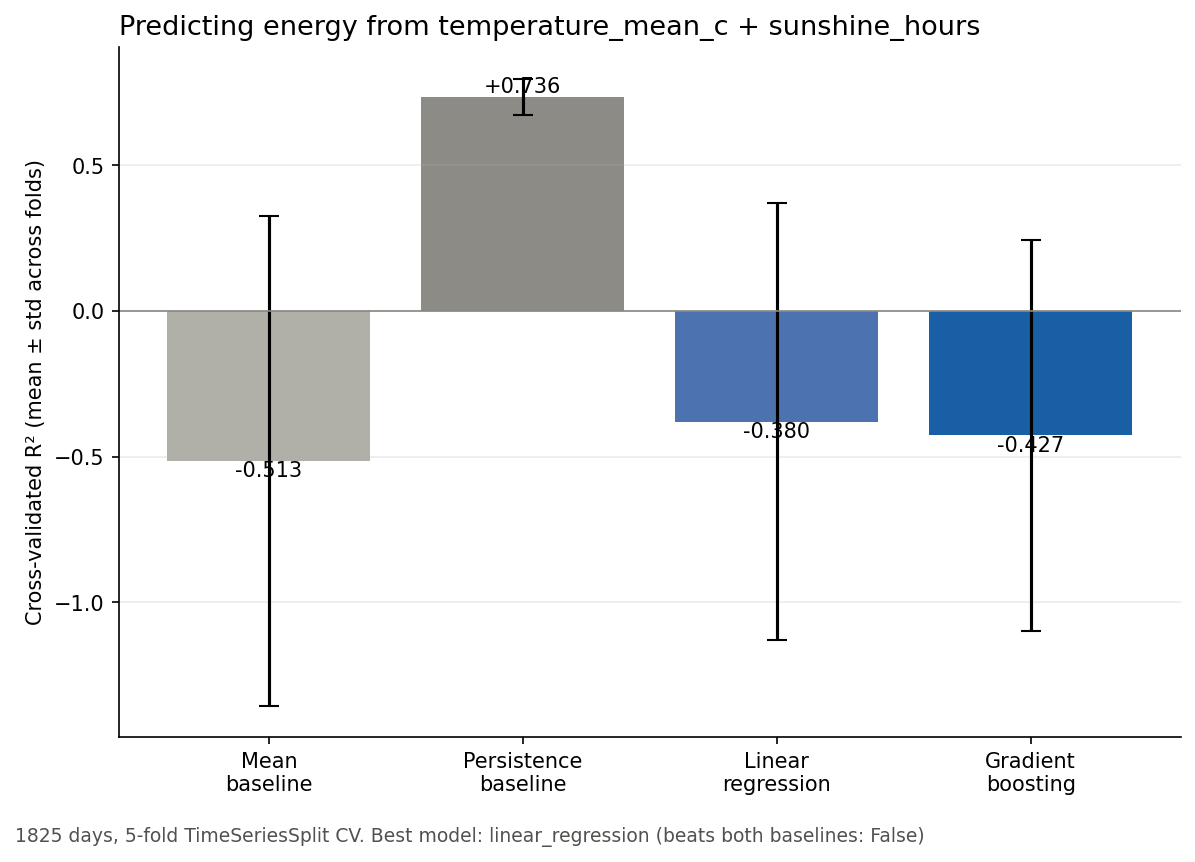

In [13]:
# Cross-validated R² comparison bar chart (4 models)
Image(os.path.join(RESULTS_DIR, "predict_report.png"))

---
## 3. Regression Analysis

### 3.1 Multicollinearity Check (VIF)

In [14]:
# VIF table all predictors should be < 5.0
vif_table

,predictor,vif,step,retained_at_step
0,sunshine_hours,2.166,0,"temperature_mean_c,precipitation_mm,sunshine_h..."
1,temperature_mean_c,1.888,0,"temperature_mean_c,precipitation_mm,sunshine_h..."
2,precipitation_mm,1.408,0,"temperature_mean_c,precipitation_mm,sunshine_h..."


No multicollinearity issues: all VIFs < 2.17 (temperature_mean_c: 1.888, precipitation_mm: 1.408, sunshine_hours: 2.166). All three predictors were retained.

### 3.2 Nested Model F-test (Model 1 vs. Model 2)

In [15]:
# F-test comparison
comparison_table

,Unnamed: 0,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,0,79752.0,2102.838206,0.0,NaN,NaN,NaN
1,1,79743.0,2097.328836,9.0,5.50937,23.274775,3.877683e-40


The F = 23.27, p < 0.001; shows the inclusion of the seasonal interactions (Model 2) provides additional statistically significant explanatory value above the basic additive model (Model 1). There truly is an interaction between the effects of the weather on energy across different seasons.

However, the decrease in the SSR value is just 5.51 units (2102.84 vs. 2097.33) a decrease of 0.26% against a base of 2,100 units. This is a textbook case of statistical significance without practical significance: with ~80,000 observations, even a 0.26% improvement in SSR produces p < 0.001.

### 3.3 Effective Seasonal Slopes

In [16]:
# Effective slope of each predictor within each season
seasonal_slopes.pivot_table(
    index="predictor", columns="season", values="effective_slope"
).round(5)

season,Autumn,Spring,Summer,Winter
predictor,,,,
precipitation_mm,-0.00044,-0.00053,0.00114,0.00080
sunshine_hours,0.00071,-0.00135,0.00030,0.00511
temperature_mean_c,0.00195,0.00118,0.00015,-0.00222


**Interpretation**
- **Temperature:** Is the only predictor whose direction reverses across seasons. In winter a 1°C rise is associated with a **0.0022 drop** in Energy, while in the other three seasons the relation is positive, but very weak (+0.0002 to +0.0020 per 1°C). The sign reversal can give us a peak on how the pooled model without seasonal interaction would average the winter effects and produce a null effect. 
- **Sunlight:** An extra hour of sunlight causes a **+0.0051 increase** in energy in Winter. It is the strongest weather effect on energy identified in the research. However, it vanishes in Summer and flips negative in Spring.

- **Rain:** There are no statistically significant effects (p-values 0.10–0.63), with a coefficient ranging from –0.001 to +0.001. surprisingly it also flips direction twice across the seasons with no clear pattern.

Seasonal interaction is real(F=23.27, p <0.001) but driven almost entirely by the winter sunshine and winter temperature. Winter is the season where temperature has the clearest and strongest grip on Energy. The Winter sunshine effect likely reflects the relative rarity of bright days in German winters a sunny winter day may coincide with a distinct listening context that rainy winter days do not.




temperature_mean_c


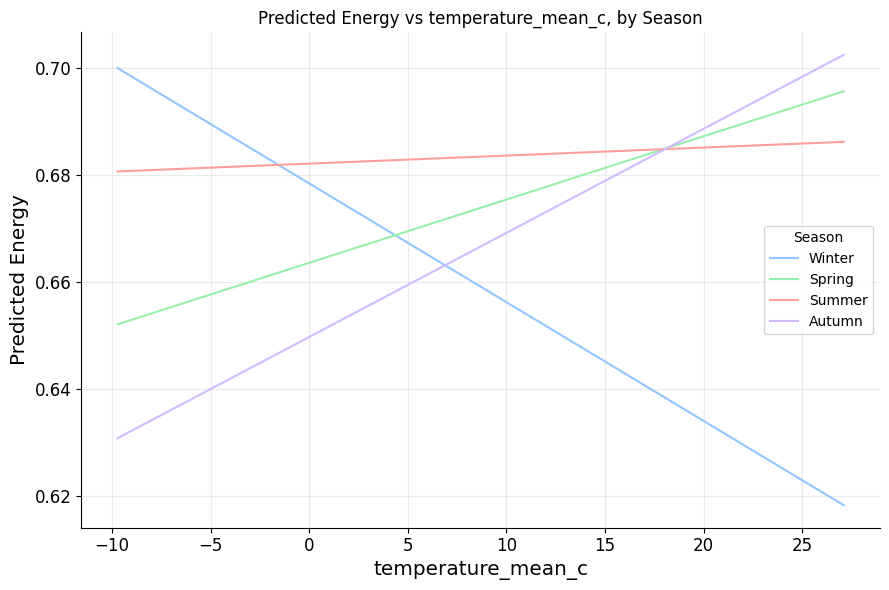


precipitation_mm


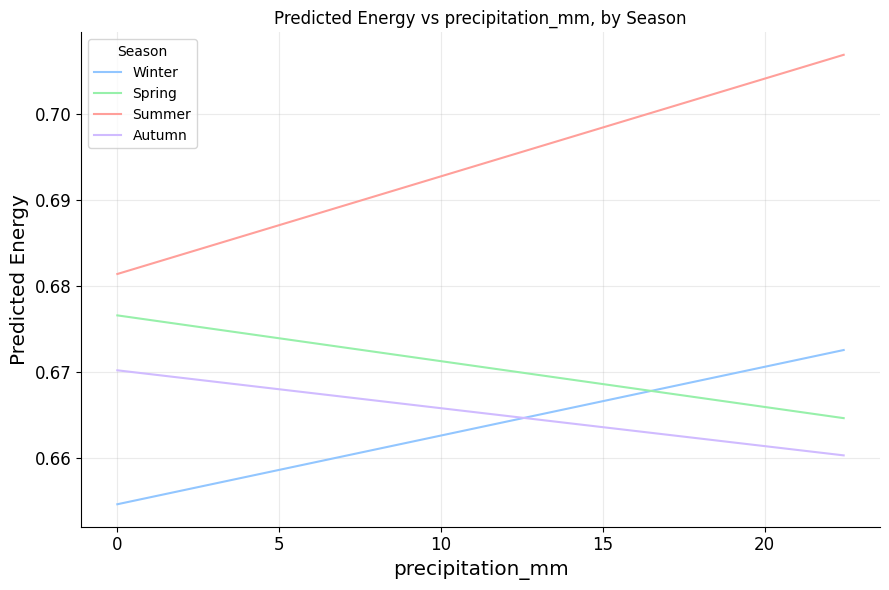


sunshine_hours


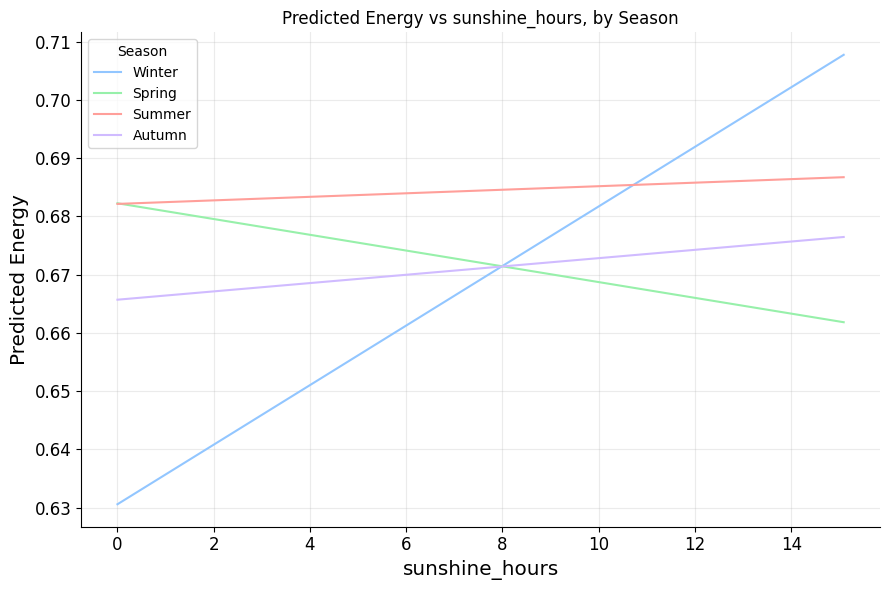

In [17]:
# Seasonal effect line plots: predicted Energy vs each predictor, one line per season
PREDICTORS = ["temperature_mean_c", "precipitation_mm", "sunshine_hours"]
for predictor in PREDICTORS:
    plot_path = os.path.join(RESULTS_DIR, f"plot_{predictor}.png")
    if os.path.exists(plot_path):
        print(f"\n{predictor}")
        display(Image(plot_path))

### 3.4 Hold-out Predictive Performance

In [18]:
# Simple train/test split predictive metrics (temperature + sunshine only)
predictive_metrics

,model,r2,rmse,mae,n_train,n_test,predictors,target
0,linear_regression,0.00268,0.1629,0.13176,63807,15952,"temperature_mean_c,sunshine_hours",energy


Linear regression on temperature + sunshine **R² = 0.00268**, RMSE = 0.1629, MAE = 0.1318 (n_test = 15,952).

This confirms the cross-validation result that weather explains essentially **0.27% of the variance** in energy on unseen days.

---
## 5. Caveats
**Persistence dominates:** The persistence baseline accounts for 73.6% of variance, which corresponds to the observation that daily charts move slowlysame songs are charting day after day and their Energy profile does not change much. Weather cannot beat such persistence.

**Statiscally Significant, yet practically insignificant interactions:** The F-test confirms that interactions are significant, yet the improvement in SSR is only 5.51 units (0.26% of baseline). At around 80,000 observations, even this almost microscopic difference is significant at p < 0.001.

**Large cross-validation standard error:** Standard deviation of R² ±0.75 suggests large dependence on particular period. Fold 2 had R² ≈ -1.7, whereas folds 0 and 4 had R² ≈ +0.05-0.10. This inconsistency adds another reason why weather does not seem like a good predictor of Energy.

**Insignificant seasonal slopes:** The most significant seasonal effect is sunshine in Winter (+0.0051 per hour). For 5 hours of extra sunshine in winter the corresponding change in Energy on the 0-1 scale will be only +0.025.

---
## 6. Takeaway

A model using daily temperature and sunshine duration **cannot accurately predict** the daily Energy level of the German Spotify Top 100. Weather models return **negative R² values** (−0.38 to −0.43) which is performing worse than simply predicting the mean. The persistence baseline predicting yesterday's Energy achieves R² = 0.736, confirming that **73.6% of daily energy variation is chart inertia**, not weather.

While seasonal interactions are statistically significant (F = 23.27, p < 0.001), the practical magnitude is negligible looking at the largest effect (sunshine in Winter) changes energy by only 0.025 for a 5-hour swing in sunshine.

In conclusion, its evident tath weather is a poor predictor of daily music energy. Although some effects are statistically significant, they are too small to be practically meaningful, indicating that chart composition has a much greater influence on listening patterns than daily weather.